# Data Understanding & Data Quality

## 1. Introduction

This notebook explores the cleaned AML transaction dataset **before Feature Engineering**.

The objectives are to:
- Understand the dataset structure, columns, and data types.
- Assess missing values and duplicate records.
- Explore numerical and categorical feature distributions.
- Investigate potential outliers without automatically removing them.
- Explore the target distribution and selected transaction patterns.
- Summarize data-quality findings before proceeding to Feature Engineering.


## 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")


## 3. Upload and Load Dataset

Upload the cleaned dataset **before Feature Engineering**. Expected columns include the original transaction fields such as `Time`, `Date`, `Sender_account`, `Receiver_account`, `Amount`, currency/location fields, `Payment_type`, and `Is_laundering`.

Supported formats: CSV and Excel.

In [2]:
from google.colab import files

uploaded = files.upload()
if not uploaded:
    raise ValueError("No file was uploaded. Please upload the pre-Feature-Engineering dataset.")

file_name = next(iter(uploaded))
file_path = Path(file_name)

if file_path.suffix.lower() == ".csv":
    df = pd.read_csv(file_path)
elif file_path.suffix.lower() in [".xlsx", ".xls"]:
    df = pd.read_excel(file_path)
else:
    raise ValueError("Unsupported file format. Please upload a CSV or Excel file.")

print(f"Loaded file: {file_name}")
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())


Saving money_laundring_clean.csv to money_laundring_clean.csv
Loaded file: money_laundring_clean.csv
Dataset shape: 97,066 rows × 12 columns


,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
0,10:51:48,2022-10-07,3884364796,3678154204,92.610,Euros,UK pounds,UK,UK,Credit card,0,Normal_Small_Fan_Out
1,19:44:48,2022-10-11,7900125583,3009831077,"5,157.160",UK pounds,UK pounds,UK,Japan,Cross-border,1,Behavioural_Change_2
2,8:17:22,2022-10-15,8175367805,3447405915,"7,426.990",UK pounds,UK pounds,UAE,UK,Cheque,0,Normal_Fan_Out
3,15:04:00,2022-10-18,786553572,6980069974,"3,391.180",UK pounds,UK pounds,US,Nigeria,ACH,0,Normal_Small_Fan_Out
4,4:48:34,2022-10-29,2839583258,1512033381,"6,951.290",US dollars,US dollars,UK,Germany,Debit card,0,Normal_Fan_In


## 4. Dataset Overview

In [3]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nRandom sample:")
display(df.sample(min(5, len(df)), random_state=42))


Dataset shape: (97066, 12)

Column names:
['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount', 'Payment_currency', 'Received_currency', 'Sender_bank_location', 'Receiver_bank_location', 'Payment_type', 'Is_laundering', 'Laundering_type']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 97066 entries, 0 to 97065
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Time                    97066 non-null  object 
 1   Date                    97066 non-null  object 
 2   Sender_account          97066 non-null  int64  
 3   Receiver_account        97066 non-null  int64  
 4   Amount                  97066 non-null  float64
 5   Payment_currency        97066 non-null  object 
 6   Received_currency       97066 non-null  object 
 7   Sender_bank_location    97066 non-null  object 
 8   Receiver_bank_location  97066 non-null  object 
 9   Payment_type            97066 n

,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
64576,7:07:57,2022-10-30,591073496,3748363635,"8,945.880",UK pounds,US dollars,UK,UK,Cross-border,0,Normal_Small_Fan_Out
67014,20:37:29,2022-10-08,2733277823,7081732547,"6,427.580",Euros,UK pounds,UK,US,Cheque,0,Normal_Fan_Out
923,22:38:26,2022-10-09,2015832676,811836341,"3,619.710",UK pounds,US dollars,Germany,UK,Cheque,0,Normal_Small_Fan_Out
17454,22:51:32,2022-11-06,7119134102,3689146289,"8,685.110",US dollars,UK pounds,UK,US,Debit card,0,Normal_Small_Fan_Out
93415,5:15:39,2022-11-02,7616106156,2170399894,"8,824.100",UK pounds,UK pounds,UK,Germany,Cheque,0,Normal_Fan_In


### 4.1 Data Dictionary

Review the available columns and their meanings. Update descriptions if the actual dataset schema differs.

In [4]:
data_dictionary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": [str(df[col].dtype) for col in df.columns],
    "Non-Null Count": [df[col].notna().sum() for col in df.columns],
    "Unique Values": [df[col].nunique(dropna=True) for col in df.columns]
})
display(data_dictionary)


,Column,Data Type,Non-Null Count,Unique Values
0,Time,object,97066,46670
1,Date,object,97066,37
2,Sender_account,int64,97066,30865
3,Receiver_account,int64,97066,49056
4,Amount,float64,97066,73531
5,Payment_currency,object,97066,7
6,Received_currency,object,97066,7
7,Sender_bank_location,object,97066,7
8,Receiver_bank_location,object,97066,7
9,Payment_type,object,97066,8


## 5. Data Quality Assessment

This section measures missing values and exact duplicate rows. No records are removed here.

### 5.1 Missing Values

In [5]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage (%)": (df.isna().mean() * 100).round(3)
}).sort_values("Missing Count", ascending=False)

display(missing_summary)

missing_to_plot = missing_summary[missing_summary["Missing Count"] > 0]
if not missing_to_plot.empty:
    plt.figure(figsize=(10, 5))
    plt.bar(missing_to_plot.index, missing_to_plot["Missing Percentage (%)"])
    plt.title("Missing Values by Column")
    plt.xlabel("Column")
    plt.ylabel("Missing Values (%)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")


,Missing Count,Missing Percentage (%)
Time,0,0.000
Date,0,0.000
Sender_account,0,0.000
Receiver_account,0,0.000
Amount,0,0.000
Payment_currency,0,0.000
Received_currency,0,0.000
Sender_bank_location,0,0.000
Receiver_bank_location,0,0.000
Payment_type,0,0.000


No missing values found.


### 5.2 Duplicate Records

In [6]:
duplicate_count = int(df.duplicated().sum())
duplicate_percentage = duplicate_count / len(df) * 100 if len(df) else 0

print(f"Exact duplicate rows: {duplicate_count:,}")
print(f"Duplicate percentage: {duplicate_percentage:.3f}%")

if duplicate_count:
    display(df[df.duplicated(keep=False)].head(10))


Exact duplicate rows: 0
Duplicate percentage: 0.000%


## 6. Data Type and Value Checks

Inspect types and basic validity. Account identifiers are identifiers rather than continuous numeric measurements; if they were read as numbers, consider loading them as strings in a later controlled data-preparation step.

In [7]:
display(pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Unique Values": df.nunique(dropna=True),
    "Missing Values": df.isna().sum()
}))

for col in ["Is_laundering"]:
    if col in df.columns:
        print(f"\n{col} value counts:")
        display(df[col].value_counts(dropna=False).to_frame("Count"))


,Data Type,Unique Values,Missing Values
Time,object,46670,0
Date,object,37,0
Sender_account,int64,30865,0
Receiver_account,int64,49056,0
Amount,float64,73531,0
Payment_currency,object,7,0
Received_currency,object,7,0
Sender_bank_location,object,7,0
Receiver_bank_location,object,7,0
Payment_type,object,8,0



Is_laundering value counts:


,Count
Is_laundering,
0,74585
1,22481


## 7. Numerical Feature Analysis

The pre-Feature-Engineering dataset is expected to contain `Amount` as its main continuous numeric transaction feature. Other numeric-looking columns may be account identifiers or labels and should not automatically be treated as continuous measurements.

In [8]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
id_like = [c for c in numeric_cols if "account" in c.lower() or c.lower().endswith("_id")]
numeric_analysis_cols = [c for c in numeric_cols if c not in id_like and c != "Is_laundering"]

print("Numeric columns:", numeric_cols)
print("Identifier-like numeric columns excluded from distribution plots:", id_like)
print("Columns selected for numerical analysis:", numeric_analysis_cols)

if numeric_analysis_cols:
    display(df[numeric_analysis_cols].describe().T)
else:
    print("No suitable numeric measurement columns found.")


Numeric columns: ['Sender_account', 'Receiver_account', 'Amount', 'Is_laundering']
Identifier-like numeric columns excluded from distribution plots: ['Sender_account', 'Receiver_account']
Columns selected for numerical analysis: ['Amount']


,count,mean,std,min,25%,50%,75%,max
Amount,"97,066.000","15,692.870","168,804.989",0.010,"2,303.605","5,911.295","10,077.475","6,213,931.560"


### 7.1 Numerical Distributions

Amount Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
Amount,"97,066.000","15,692.870","168,804.989",0.010,"2,303.605","5,911.295","10,077.475","6,213,931.560"


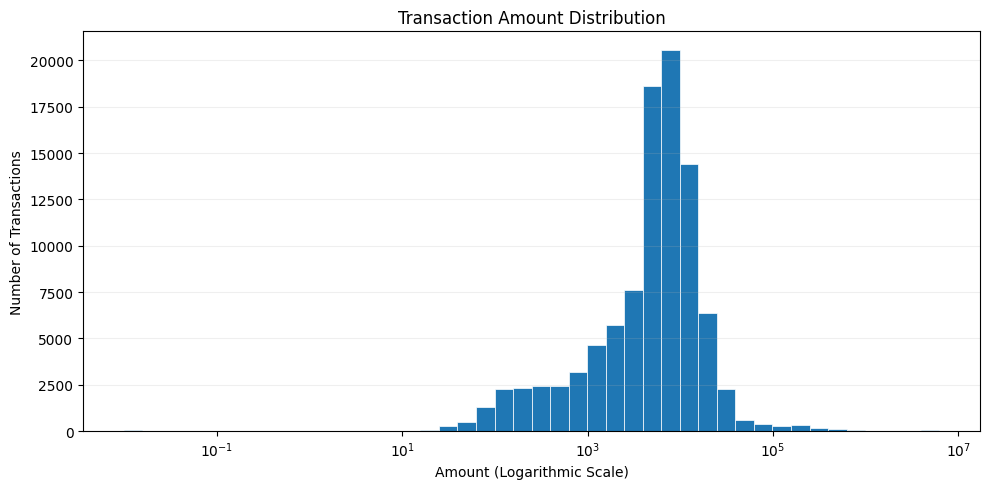

In [18]:

# Amount Distribution

amount = pd.to_numeric(df["Amount"], errors="coerce").dropna()
positive_amount = amount[amount > 0]

print("Amount Descriptive Statistics:")
display(amount.describe().to_frame().T)

# Use logarithmic bins to handle the highly right-skewed distribution
if positive_amount.nunique() > 1:

    bins = np.logspace(
        np.log10(positive_amount.min()),
        np.log10(positive_amount.max()),
        45
    )

    plt.figure(figsize=(10, 5))

    plt.hist(
        positive_amount,
        bins=bins,
        edgecolor="white",
        linewidth=0.5
    )

    plt.xscale("log")
    plt.title("Transaction Amount Distribution")
    plt.xlabel("Amount (Logarithmic Scale)")
    plt.ylabel("Number of Transactions")
    plt.grid(axis="y", alpha=0.2)

    plt.tight_layout()
    plt.show()


## 8. Outlier Investigation

Outlier flags are statistical indicators, not proof of erroneous transactions. For financial transaction data, unusually large amounts may be legitimate and potentially informative. This section identifies and visualizes potential outliers; it does **not** remove or cap them.

Q1: 2,303.605
Q3: 10,077.475
IQR: 7,773.870
Lower Bound: -9,357.200
Upper Bound: 21,738.280
Potential Outliers: 5,523 (5.69%)
99th Percentile: 105,674.690
Maximum Amount: 6,213,931.560


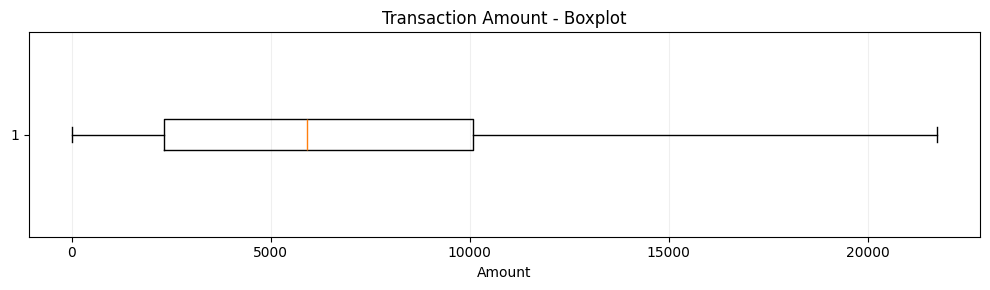

Outlier candidates are retained. No transaction records were removed.


In [19]:

# IQR Outlier Analysis

Q1 = amount.quantile(0.25)
Q3 = amount.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

potential_outliers = amount[
    (amount < lower_bound) | (amount > upper_bound)
]

outlier_percentage = (
    len(potential_outliers) / len(amount)
) * 100

print(f"Q1: {Q1:,.3f}")
print(f"Q3: {Q3:,.3f}")
print(f"IQR: {IQR:,.3f}")
print(f"Lower Bound: {lower_bound:,.3f}")
print(f"Upper Bound: {upper_bound:,.3f}")

print(
    f"Potential Outliers: {len(potential_outliers):,} "
    f"({outlier_percentage:.2f}%)"
)

print(f"99th Percentile: {amount.quantile(0.99):,.3f}")
print(f"Maximum Amount: {amount.max():,.3f}")

# Boxplot without displaying individual outlier points
plt.figure(figsize=(10, 3))

plt.boxplot(
    amount,
    vert=False,
    showfliers=False
)

plt.title("Transaction Amount - Boxplot")
plt.xlabel("Amount")
plt.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

print(
    "Outlier candidates are retained. "
    "No transaction records were removed."
)


## 9. Categorical Feature Analysis

Review the most frequent values in categorical columns. The plots show counts, not laundering rates.


Payment_currency Distribution:


,Count
Payment_currency,
UK pounds,49912
US dollars,17765
Euros,13794
Naira,5806
Dirham,3902
Yen,2968
Swiss francs,2919


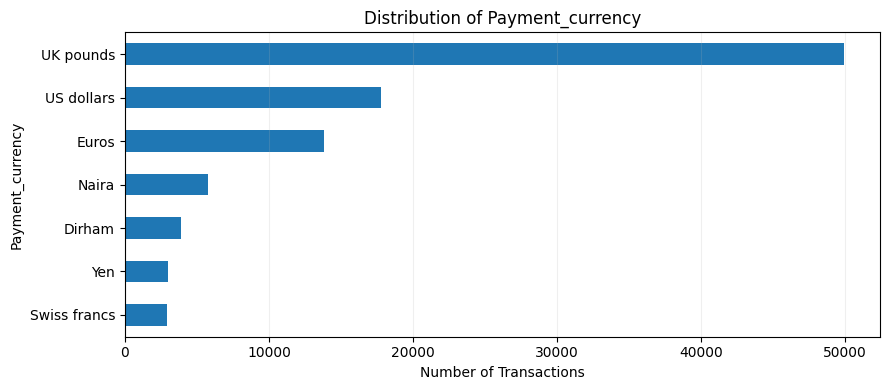


Received_currency Distribution:


,Count
Received_currency,
UK pounds,45937
US dollars,19429
Euros,14773
Naira,7015
Dirham,3930
Yen,3020
Swiss francs,2962


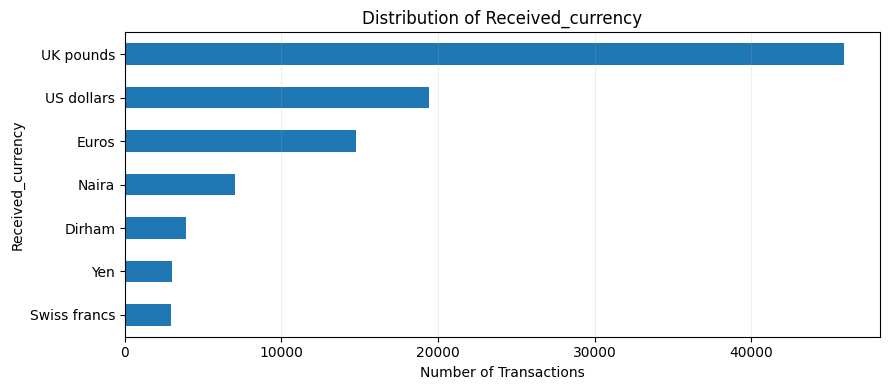


Sender_bank_location Distribution:


,Count
Sender_bank_location,
UK,50606
US,16821
Germany,9722
Nigeria,6897
UAE,5097
Switzerland,3969
Japan,3954


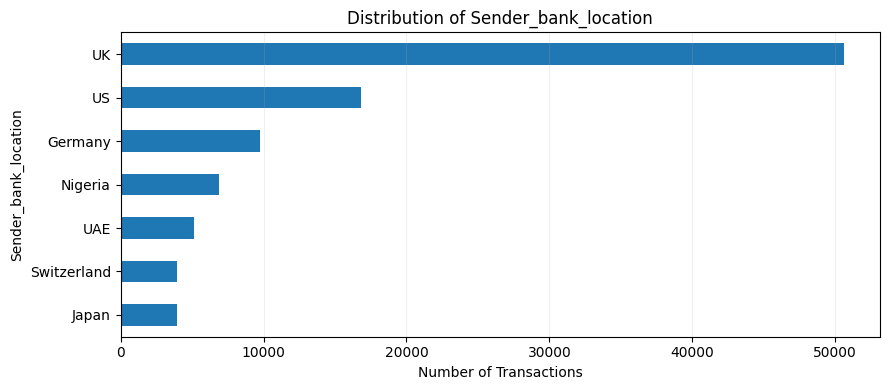


Receiver_bank_location Distribution:


,Count
Receiver_bank_location,
UK,46122
US,18504
Germany,10642
Nigeria,6852
UAE,5934
Japan,4961
Switzerland,4051


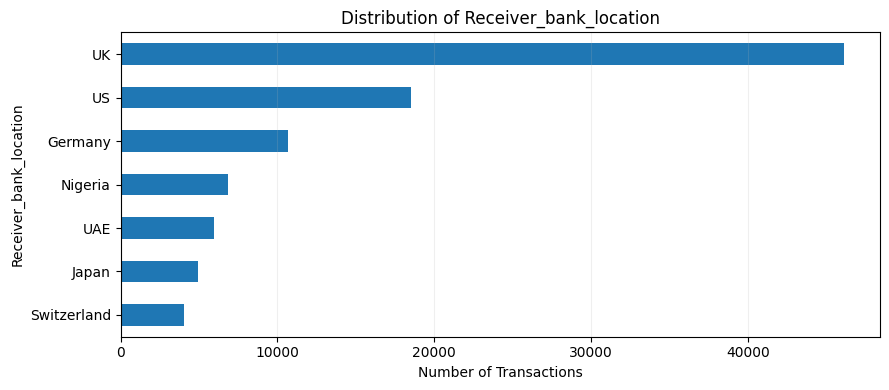


Payment_type Distribution:


,Count
Payment_type,
Credit card,19091
ACH,18705
Cheque,18344
Debit card,18246
Cross-border,12519
Cash Withdrawal,5165
Cash Deposit,4842
Unknown,154


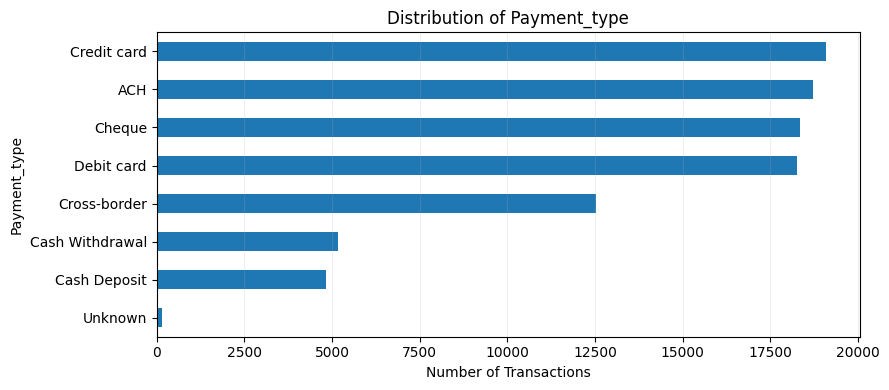

In [20]:

# Categorical Feature Analysis

categorical_cols = [
    "Payment_currency",
    "Received_currency",
    "Sender_bank_location",
    "Receiver_bank_location",
    "Payment_type"
]

for col in categorical_cols:

    counts = df[col].value_counts(dropna=False)

    print(f"\n{col} Distribution:")
    display(counts.rename("Count").to_frame())

    plt.figure(figsize=(9, 4))

    counts.sort_values().plot(
        kind="barh"
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel("Number of Transactions")
    plt.ylabel(col)
    plt.grid(axis="x", alpha=0.2)

    plt.tight_layout()
    plt.show()


## 10. Target Variable Analysis

Explore the class balance for `Is_laundering`. A class imbalance is important context for later model evaluation.

,Count,Percentage (%)
Is_laundering,,
0,74585,76.840
1,22481,23.160


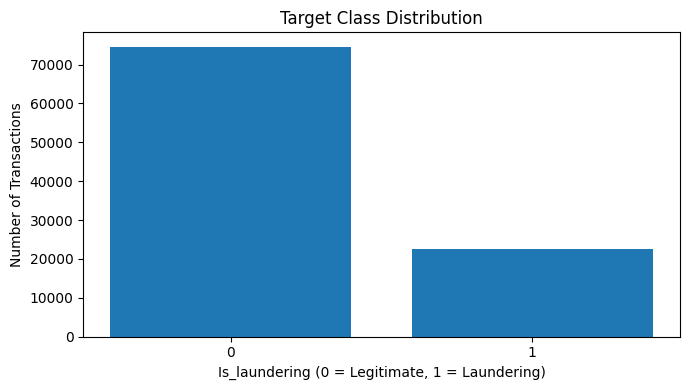

In [12]:
if "Is_laundering" in df.columns:
    target_counts = df["Is_laundering"].value_counts(dropna=False).sort_index()
    target_percentages = df["Is_laundering"].value_counts(normalize=True, dropna=False).sort_index() * 100

    target_summary = pd.DataFrame({
        "Count": target_counts,
        "Percentage (%)": target_percentages.round(2)
    })
    display(target_summary)

    plt.figure(figsize=(7, 4))
    plt.bar(target_counts.index.astype(str), target_counts.values)
    plt.title("Target Class Distribution")
    plt.xlabel("Is_laundering (0 = Legitimate, 1 = Laundering)")
    plt.ylabel("Number of Transactions")
    plt.tight_layout()
    plt.show()
else:
    print("Target column Is_laundering not found.")


## 11. Exploratory Transaction Patterns

The following plots use only columns already present in the pre-Feature-Engineering dataset. Date and time components are derived temporarily for visualization only; they are not added to `df` and no engineered dataset is saved.

### 11.1 Laundering Transactions by Payment Type

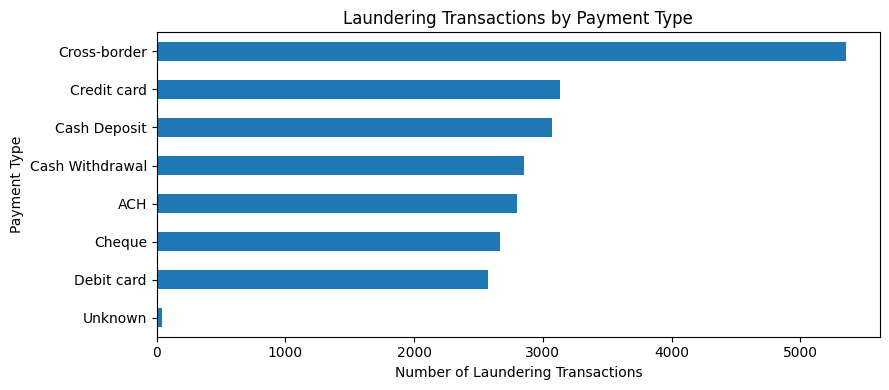

In [22]:
if {"Payment_type", "Is_laundering"}.issubset(df.columns):
    laundering_df = df[df["Is_laundering"].astype(str).isin(["1", "1.0"])]

    payment_counts = laundering_df["Payment_type"].value_counts(dropna=False)
    plt.figure(figsize=(9, 4))
    payment_counts.sort_values().plot(kind="barh")
    plt.title("Laundering Transactions by Payment Type")
    plt.xlabel("Number of Laundering Transactions")
    plt.ylabel("Payment Type")
    plt.tight_layout()
    plt.show()
else:
    print("Payment_type or Is_laundering column not found.")




### 11.2 Laundering Rate by Payment Type

Rates are more comparable than raw counts when category sizes differ. Categories with very few records should be interpreted cautiously.

,Transactions,Laundering_Rate,Laundering_Rate (%)
Payment_type,,,
Cash Deposit,4842,0.634,63.404
Cash Withdrawal,5165,0.552,55.198
Cross-border,12519,0.427,42.743
Unknown,154,0.253,25.325
Credit card,19091,0.164,16.395
ACH,18705,0.150,14.969
Cheque,18344,0.145,14.539
Debit card,18246,0.141,14.102


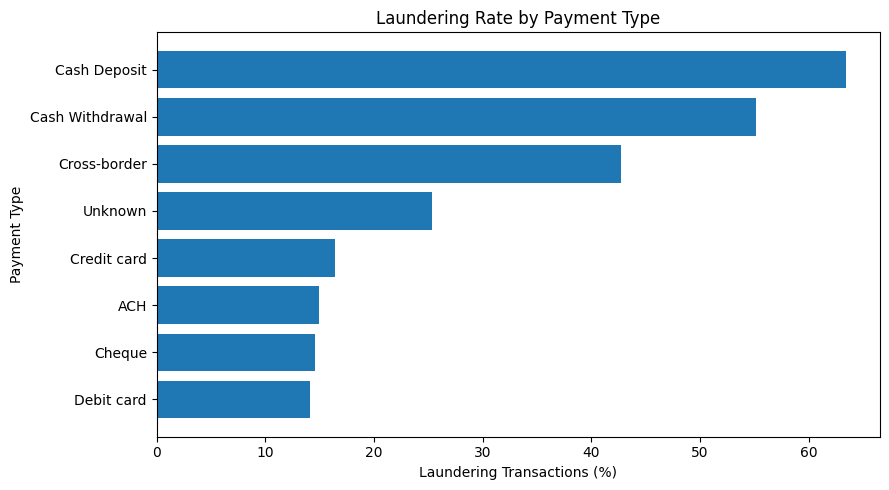

In [14]:
if {"Payment_type", "Is_laundering"}.issubset(df.columns):
    payment_rate = df.groupby("Payment_type", dropna=False)["Is_laundering"].agg(
        Transactions="count", Laundering_Rate="mean"
    )
    payment_rate["Laundering_Rate (%)"] = payment_rate["Laundering_Rate"] * 100
    display(payment_rate.sort_values("Laundering_Rate (%)", ascending=False))

    plot_rates = payment_rate.sort_values("Laundering_Rate (%)")
    plt.figure(figsize=(9, 5))
    plt.barh(plot_rates.index.astype(str), plot_rates["Laundering_Rate (%)"])
    plt.title("Laundering Rate by Payment Type")
    plt.xlabel("Laundering Transactions (%)")
    plt.ylabel("Payment Type")
    plt.tight_layout()
    plt.show()


### 11.3 Day of Week Analysis (Temporary Derivation)

This analysis temporarily derives the day of the week from the original `Date` column to visualize the number of laundering transactions across different weekdays.

The derived weekday values are used for exploratory visualization only. No new features are added to the original dataset, and no changes are made to the data.

In [24]:

# Prepare Date and Time for Temporal Analysis

if {"Date", "Time", "Is_laundering"}.issubset(df.columns):

    temp_time = pd.DataFrame({
        "Day": pd.to_datetime(
            df["Date"], errors="coerce"
        ).dt.day_name(),

        "Hour": pd.to_datetime(
            df["Time"].astype(str),
            format="%H:%M:%S",
            errors="coerce"
        ).dt.hour,

        "Is_laundering": pd.to_numeric(
            df["Is_laundering"],
            errors="coerce"
        )
    })

    day_order = [
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ]

    print("Temporal data prepared successfully.")
    print("Valid records:", len(temp_time.dropna()))

else:
    print("Required columns are missing.")


Temporal data prepared successfully.
Valid records: 97066


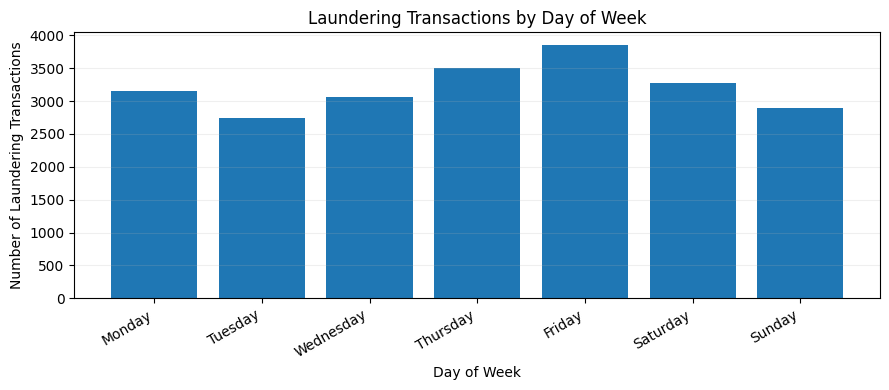

In [25]:

# Laundering Transactions by Day of Week

laundering_by_day = (
    temp_time[temp_time["Is_laundering"] == 1]["Day"]
    .value_counts()
    .reindex(day_order, fill_value=0)
)

plt.figure(figsize=(9, 4))

plt.bar(
    laundering_by_day.index,
    laundering_by_day.values
)

plt.title("Laundering Transactions by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Laundering Transactions")

plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


### 11.4 Currency Pair Analysis

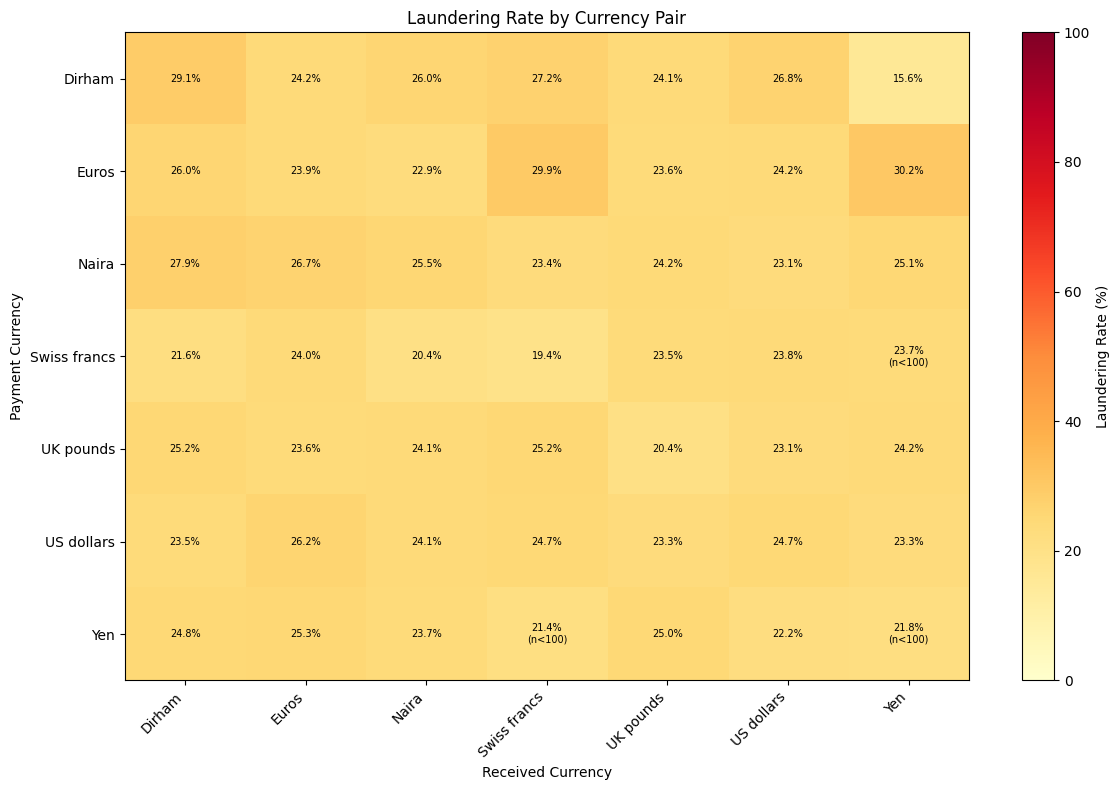

In [16]:
required_currency_cols = {"Payment_currency", "Received_currency", "Is_laundering"}
if required_currency_cols.issubset(df.columns):
    currency_rate = df.pivot_table(
        index="Payment_currency",
        columns="Received_currency",
        values="Is_laundering",
        aggfunc="mean"
    ) * 100

    currency_counts = df.pivot_table(
        index="Payment_currency",
        columns="Received_currency",
        values="Is_laundering",
        aggfunc="count"
    )

    fig, ax = plt.subplots(figsize=(12, 8))
    im = ax.imshow(currency_rate.values, cmap="YlOrRd", aspect="auto", vmin=0, vmax=100)

    for i in range(currency_rate.shape[0]):
        for j in range(currency_rate.shape[1]):
            rate = currency_rate.iloc[i, j]
            count = currency_counts.iloc[i, j]
            if pd.notna(rate):
                label = f"{rate:.1f}%"
                if pd.notna(count) and count < 100:
                    label += "\n(n<100)"
                ax.text(j, i, label, ha="center", va="center", fontsize=7)

    ax.set_xticks(range(len(currency_rate.columns)))
    ax.set_xticklabels(currency_rate.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(currency_rate.index)))
    ax.set_yticklabels(currency_rate.index)
    ax.set_xlabel("Received Currency")
    ax.set_ylabel("Payment Currency")
    ax.set_title("Laundering Rate by Currency Pair")
    fig.colorbar(im, ax=ax, label="Laundering Rate (%)")
    plt.tight_layout()
    plt.show()
else:
    print("Currency or target columns not found; currency-pair analysis skipped.")


## 12. Data Quality Summary

Generate a concise summary of the main checks. Review the results before deciding whether any further cleaning is justified.

In [23]:

# Final Data Quality Summary

quality_summary = pd.DataFrame({
    "Check": [
        "Total Rows",
        "Total Columns",
        "Missing Values",
        "Exact Duplicate Rows",
        "Potential Amount Outliers",
        "Unknown Payment Types"
    ],

    "Result": [
        len(df),
        df.shape[1],
        int(df.isna().sum().sum()),
        int(df.duplicated().sum()),
        len(potential_outliers),
        int((df["Payment_type"] == "Unknown").sum())
    ]
})

display(quality_summary)

print("\nKey Data Quality Observations:")

print("- No missing values were detected.")
print("- No exact duplicate records were detected.")
print("- Amount contains potential statistical outliers.")
print("- Unknown values exist in Payment_type.")
print("- Laundering_type must be excluded from model features.")


,Check,Result
0,Total Rows,97066
1,Total Columns,12
2,Missing Values,0
3,Exact Duplicate Rows,0
4,Potential Amount Outliers,5523
5,Unknown Payment Types,154



Key Data Quality Observations:
- No missing values were detected.
- No exact duplicate records were detected.
- Amount contains potential statistical outliers.
- Unknown values exist in Payment_type.
- Laundering_type must be excluded from model features.


## 13. Conclusion

Complete this section after reviewing the notebook outputs.

Document:
- The final dataset dimensions and column structure.
- Missing-value findings and any unresolved missingness.
- Duplicate-record findings.
- Outlier observations for transaction amounts.
- Target class distribution and any imbalance.
- Any data-quality concerns to address before Feature Engineering.

**Next stage:** Feature Engineering.